# Pertemuan 7 — Praktikum 3: HNSW

HNSW (*Hierarchical Navigable Small World*) adalah algoritma ANN berbasis graf yang dikembangkan Malkov dan Yashunin pada tahun 2016. Data vektor direpresentasikan sebagai simpul graf, dan hubungan antar simpul ditentukan oleh kedekatan jaraknya.

Struktur HNSW bertingkat. Pada level teratas hanya terdapat sedikit simpul dengan koneksi yang jarang, sedangkan pada level terbawah terdapat seluruh simpul dengan koneksi yang lebih rapat. Pencarian dimulai dari level atas untuk menemukan area umum tempat query berada, lalu turun ke level yang lebih rendah hingga menemukan tetangga terdekat di level dasar. Strategi ini disebut *greedy search*, yaitu perpindahan dari satu simpul ke simpul tetangga yang lebih dekat sampai tidak ada lagi yang lebih dekat.

Sumber: [Praktikum 3](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/praktikum-3) dan [HNSW](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors/hnsw).

## 1. Pemasangan pustaka

Pustaka HNSW dipasang melalui paket `hnswlib`. Pada lingkungan yang dipakai laporan ini, `hnswlib` sudah tersedia.

In [1]:
# Pemasangan sekali saja
# !pip install hnswlib

import time

import hnswlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

## 2. Percobaan — Exact NN dibandingkan HNSW

Percobaan memakai 1.000 data acak dua dimensi dengan lima tetangga terdekat. Pencarian exact dilakukan dengan `NearestNeighbors` bermetode *brute force*, sedangkan pencarian HNSW dilakukan melalui `hnswlib.Index` dengan parameter `M = 16` dan `ef_construction = 100`.

Parameter `ef` pada tahap pencarian mengatur pertukaran antara kecepatan dan akurasi. Nilai `ef` yang lebih besar membuat pencarian memeriksa lebih banyak kandidat, sehingga hasilnya lebih akurat tetapi lebih lambat.

In [2]:
# ===========================
# 1. Buat data 2D acak
# ===========================
np.random.seed(42)
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
# Inisialisasi index HNSW
p = hnswlib.Index(space='l2', dim=dim)  # Ukuran maksimum elemen yang bisa ditampung
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Tambahkan data
p.add_items(data)

# Set parameter pencarian
p.set_ef(50)  # tradeoff speed vs accuracy

start = time.time()
labels, distances_hnsw = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances_hnsw)
print("Waktu:", end - start, "detik")

=== Exact NN ===
Indices: [[137 170 750 316 991]]
Distances: [[0.01144331 0.0278216  0.02824018 0.03417073 0.04514859]]
Waktu: 0.02420806884765625 detik

=== HNSW ===
Indices: [[137 170 750 316 991]]
Distances: [[0.00013095 0.00077404 0.00079751 0.00116764 0.0020384 ]]
Waktu: 5.2928924560546875e-05 detik


Hasil HNSW menghasilkan indeks tetangga yang sama dengan hasil exact pada percobaan ini, sementara waktu pencariannya lebih singkat. Kesamaan hasil tersebut terjadi karena data masih kecil dan nilai `ef` yang dipakai cukup besar, sehingga graf yang ditelusuri mampu menemukan tetangga yang sebenarnya.

Nilai jarak yang dilaporkan kedua metode berbeda walaupun indeksnya sama. Pustaka `hnswlib` dengan `space='l2'` mengembalikan kuadrat jarak Euclidean, sedangkan `NearestNeighbors` mengembalikan jarak Euclidean. Sebagai contoh, jarak 0,011443 pada hasil exact sama dengan 0,000131 pada hasil HNSW karena $0{,}011443^2 pprox 0{,}000131$. Urutan tetangga yang dihasilkan tetap identik karena pengkuadratan tidak mengubah urutan nilai.

## 3. Visualisasi hasil pencarian

Hasil kedua cara digambarkan agar posisi query dan tetangga terdekatnya terlihat jelas.

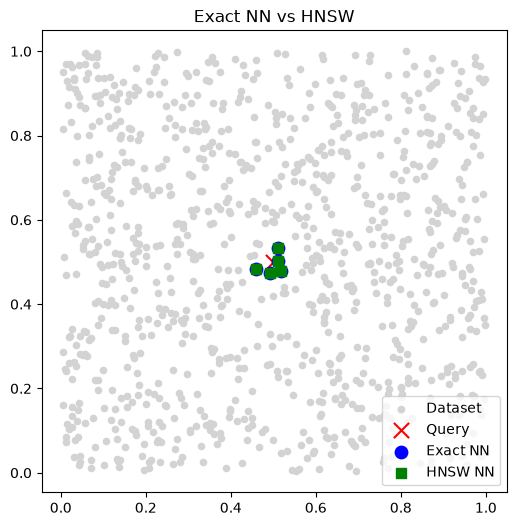

In [3]:
plt.figure(figsize=(6, 6))
plt.scatter(data[:, 0], data[:, 1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[:, 0], query[:, 1], c="red", marker="x", s=120, label="Query")
plt.scatter(data[indices[0], 0], data[indices[0], 1], c="blue", s=80, label="Exact NN")
plt.scatter(data[labels[0], 0], data[labels[0], 1], c="green", s=50, marker="s", label="HNSW NN")
plt.legend()
plt.title("Exact NN vs HNSW")
plt.show()

## 4. Tabel percobaan pengaruh metrik, jumlah data, dan dimensi

Percobaan dilanjutkan dengan memvariasikan metrik jarak (`l2` dan `ip`), jumlah data (1.000 dan 1.000.000), serta jumlah dimensi (2 dan 5). Pada HNSW, metrik `ip` (*inner product*) mengembalikan jarak yang semakin besar ketika vektor semakin mirip, sehingga hasilnya dibandingkan dengan exact NN bermetrik yang sama.

In [4]:
def uji_hnsw(n_data, dim, space, k=5, M=16, ef_construction=100, ef=50, seed=42):
    # Membandingkan exact NN dengan HNSW untuk satu kombinasi parameter
    rng = np.random.default_rng(seed)
    data = rng.random((n_data, dim)).astype(np.float32)
    titik = np.full((1, dim), 0.5, dtype=np.float32)

    start = time.perf_counter()
    if space == 'l2':
        jarak = np.linalg.norm(data - titik, axis=1)
        idx_exact = np.argsort(jarak)[:k]
    else:
        skor = data @ titik[0]
        idx_exact = np.argsort(-skor)[:k]
    waktu_exact = (time.perf_counter() - start) * 1000

    p = hnswlib.Index(space=space, dim=dim)
    p.init_index(max_elements=n_data, ef_construction=ef_construction, M=M)
    p.add_items(data)
    p.set_ef(ef)

    start = time.perf_counter()
    idx_hnsw, jarak_hnsw = p.knn_query(titik, k=k)
    waktu_hnsw = (time.perf_counter() - start) * 1000

    return idx_exact.reshape(1, -1), idx_hnsw, waktu_exact, waktu_hnsw


kombinasi = [
    ('l2', 1_000, 2),
    ('l2', 1_000_000, 2),
    ('l2', 1_000, 5),
    ('l2', 1_000_000, 5),
    ('ip', 1_000, 2),
    ('ip', 1_000_000, 2),
    ('ip', 1_000, 5),
    ('ip', 1_000_000, 5),
]

baris = []
for space, n_data, dim in kombinasi:
    idx_exact, idx_hnsw, waktu_exact, waktu_hnsw = uji_hnsw(n_data, dim, space)
    baris.append({
        "Metrik": space,
        "Jumlah data": f"{n_data:,}".replace(",", "."),
        "Dimensi": dim,
        "Index Exact NN": str([int(x) for x in idx_exact[0]]),
        "Index HNSW": str([int(x) for x in idx_hnsw[0]]),
        "Waktu Exact (ms)": round(waktu_exact, 4),
        "Waktu HNSW (ms)": round(waktu_hnsw, 4),
    })

tabel_hnsw = pd.DataFrame(baris)
display(tabel_hnsw)

,Metrik,Jumlah data,Dimensi,Index Exact NN,Index HNSW,Waktu Exact (ms),Waktu HNSW (ms)
0,l2,1.000,2,"[843, 634, 372, 70, 737]","[843, 634, 372, 70, 737]",0.2567,0.0150
1,l2,1.000.000,2,"[19638, 786703, 328755, 620323, 897494]","[19638, 786703, 328755, 620323, 897494]",98.6216,0.0384
2,l2,1.000,5,"[694, 534, 99, 859, 766]","[694, 534, 99, 859, 766]",0.1018,0.0252
3,l2,1.000.000,5,"[289393, 11237, 247737, 16575, 776364]","[289393, 11237, 247737, 16575, 776364]",101.5308,0.0573
4,ip,1.000,2,"[936, 306, 263, 457, 719]","[936, 306, 263, 457, 719]",0.0846,0.0178
5,ip,1.000.000,2,"[99583, 834419, 945126, 724665, 124376]","[99583, 834419, 945126, 724665, 124376]",87.1487,0.0238
6,ip,1.000,5,"[702, 182, 742, 312, 754]","[702, 182, 742, 312, 754]",0.0782,0.0227
7,ip,1.000.000,5,"[656271, 701183, 741004, 842877, 639942]","[656271, 701183, 741004, 842877, 639942]",88.5703,0.0335


Tabel di atas memperlihatkan bahwa HNSW menghasilkan indeks yang sama dengan pencarian exact pada seluruh kombinasi, termasuk pada data satu juta. Waktu pencariannya jauh lebih singkat dan hampir tidak berubah ketika jumlah data bertambah dari 1.000 menjadi 1.000.000, karena pencarian pada graf hanya menelusuri sebagian kecil simpul. Sifat ini yang membuat HNSW sering dianggap sebagai algoritma ANN dengan kinerja terbaik pada CPU.

## Kesimpulan

HNSW membangun graf bertingkat yang memungkinkan pencarian dilakukan secara bertahap, dari level yang jarang menuju level yang rapat. Hasil pencariannya pada percobaan ini sama dengan pencarian exact, dengan waktu yang jauh lebih singkat dan stabil terhadap pertambahan jumlah data. Parameter `M` dan `ef_construction` memengaruhi pembangunan graf, sedangkan parameter `ef` mengatur pertukaran antara kecepatan dan akurasi pada saat pencarian.